# PRE 432 — Lecture 2 Practical
## Edge and Corner Detection using a Chessboard

### 1. Load the image
I converted the image to grayscale and applied a little Gaussian smoothing for Sobel and Canny.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# Read the chessboard
image = cv2.imread("chessboard.jpg")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 1)

print("Image size:", gray.shape[1], "x", gray.shape[0])

Image size: 1000 x 1000


### 2. Sobel edge detection
`Gx` shows vertical boundaries, `Gy` shows horizontal boundaries, and **magnitude** combines them. I did not include the direction heat map.

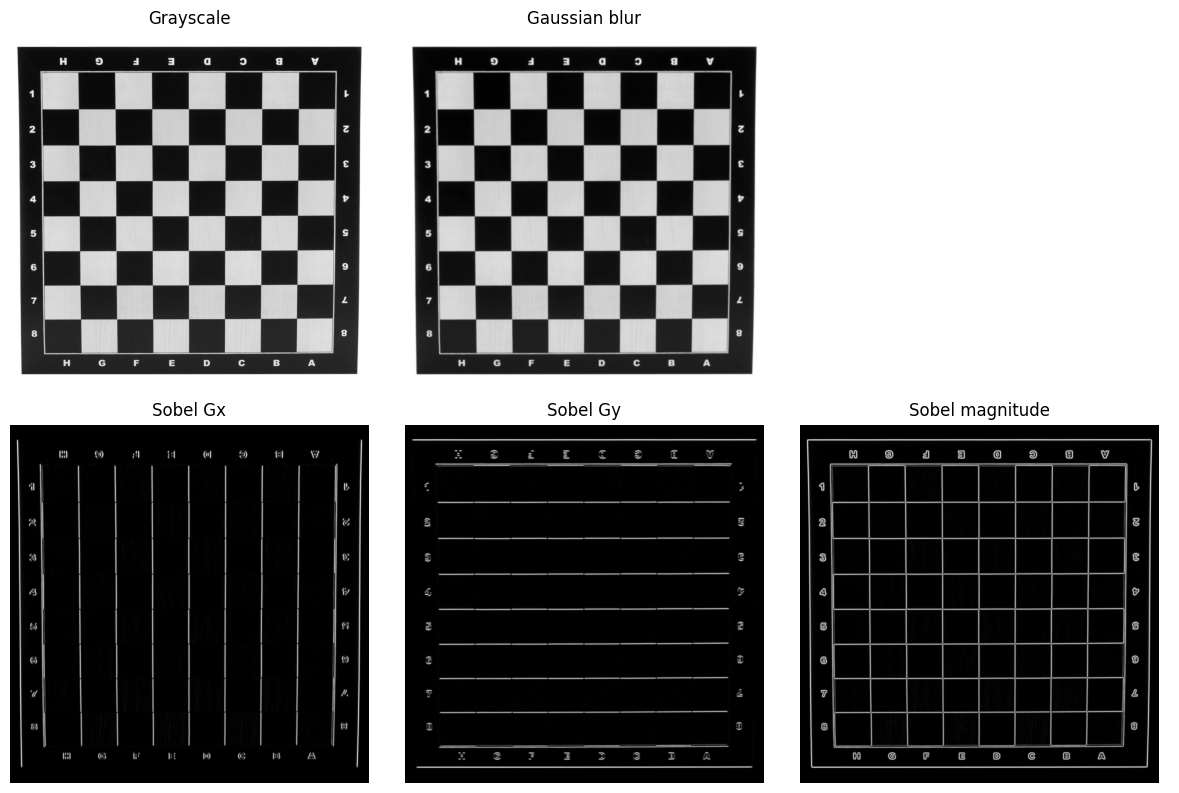

In [2]:
# Calculate Sobel gradients and magnitude
Gx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
Gy = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
magnitude = np.sqrt(Gx**2 + Gy**2)

# Show each result once
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
plots = [
    (gray, "Grayscale"),
    (blurred, "Gaussian blur"),
    (np.abs(Gx), "Sobel Gx"),
    (np.abs(Gy), "Sobel Gy"),
    (magnitude, "Sobel magnitude"),
]

positions = [axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1], axes[1, 2]]
for ax, (picture, title) in zip(positions, plots):
    ax.imshow(picture, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
axes[0, 2].axis("off")
plt.tight_layout()
plt.show()

### 3. Canny edge detection
I tested the three threshold settings from the lecture: **Low**, **Balanced**, and **High**. Higher settings should keep fewer weak edges.

Low: 25,416 edge pixels
Balanced: 25,144 edge pixels
High: 22,933 edge pixels


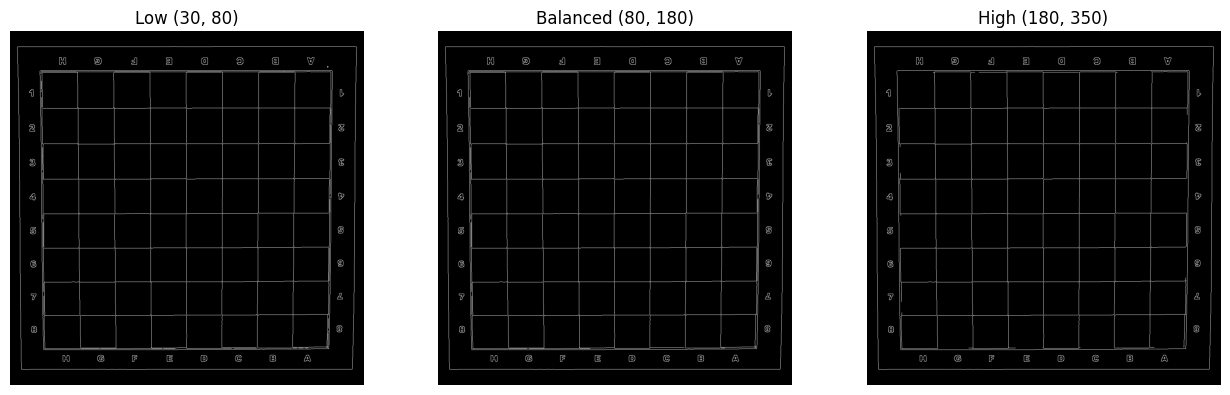

In [3]:
canny_settings = [
    ("Low", 30, 80),
    ("Balanced", 80, 180),
    ("High", 180, 350),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, low, high) in zip(axes, canny_settings):
    edges = cv2.Canny(blurred, low, high)
    count = np.count_nonzero(edges)
    ax.imshow(edges, cmap="gray")
    ax.set_title(f"{name} ({low}, {high})")
    ax.axis("off")
    print(f"{name}: {count:,} edge pixels")
plt.tight_layout()
plt.show()

### 4. Harris corner detection
Harris gives each pixel a response score: **R = det(M) − k(trace(M))²**. I used **T = p × max(R)** and kept local peaks above the threshold.

I compared `k = 0.04` and `0.06` with response thresholds of **1%** and **5%**.

k = 0.04, threshold = 1%: 252 points
k = 0.04, threshold = 5%: 245 points
k = 0.06, threshold = 1%: 232 points
k = 0.06, threshold = 5%: 228 points


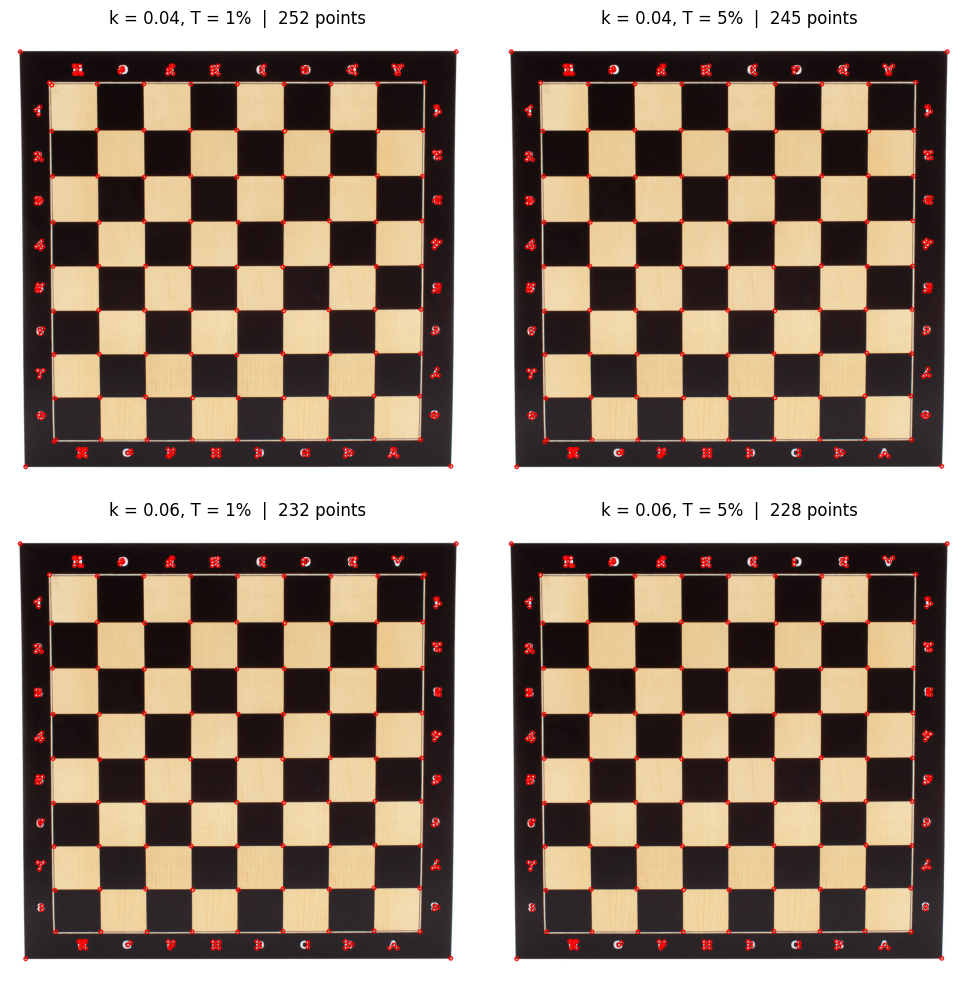

In [4]:
# Calculate Harris corners for a given k and response threshold
def harris_corners(gray_image, k=0.04, percent=0.01):
    smooth = cv2.GaussianBlur(gray_image, (5, 5), 1)
    response = cv2.cornerHarris(np.float32(smooth), 2, 3, k)
    threshold = percent * response.max()
    local_max = cv2.dilate(response, np.ones((7, 7), np.uint8))
    corners = (response > threshold) & (response == local_max)
    y, x = np.where(corners)
    return list(zip(x, y))

# Mark Harris corners in red
def draw_harris(picture, points, radius=4):
    if picture.ndim == 2:
        marked = cv2.cvtColor(picture, cv2.COLOR_GRAY2RGB)
    else:
        marked = cv2.cvtColor(picture, cv2.COLOR_BGR2RGB)
    for x, y in points:
        cv2.circle(marked, (int(x), int(y)), radius, (255, 0, 0), 2)
    return marked

harris_settings = [(0.04, 0.01), (0.04, 0.05), (0.06, 0.01), (0.06, 0.05)]
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, (k, percent) in zip(axes.flat, harris_settings):
    points = harris_corners(gray, k, percent)
    ax.imshow(draw_harris(image, points))
    ax.set_title(f"k = {k}, T = {percent:.0%}  |  {len(points)} points")
    ax.axis("off")
    print(f"k = {k}, threshold = {percent:.0%}: {len(points)} points")

plt.tight_layout()
plt.show()

### 5. FAST corner detection
FAST checks brightness around a pixel. I used the **grayscale** image with `t = 20` and `t = 60`.

FAST t = 20: 697 points
FAST t = 60: 517 points


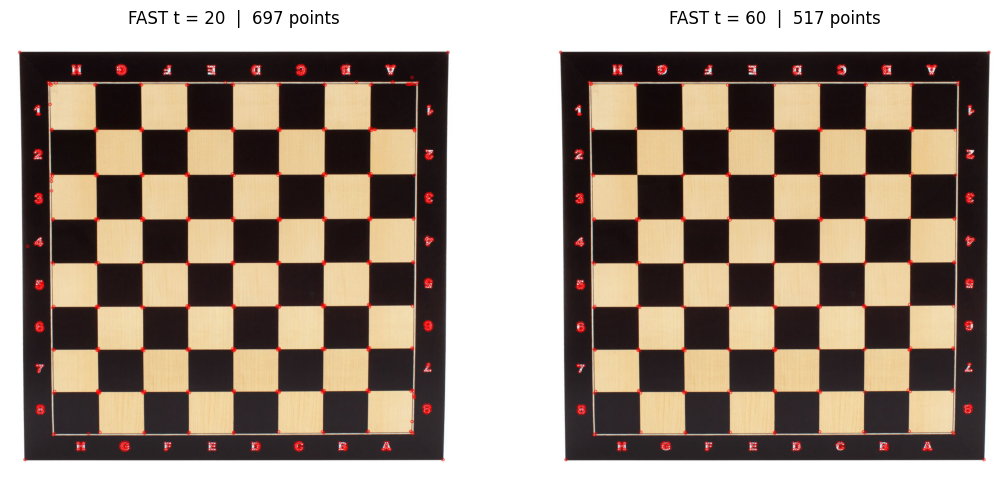

In [5]:
# Detect FAST corners
def fast_corners(gray_image, threshold=20):
    detector = cv2.FastFeatureDetector_create(
        threshold=threshold, nonmaxSuppression=True
    )
    return detector.detect(gray_image, None)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, t in zip(axes, [20, 60]):
    points = fast_corners(gray, t)
    marked = cv2.drawKeypoints(image, points, None, color=(0, 0, 255))
    ax.imshow(cv2.cvtColor(marked, cv2.COLOR_BGR2RGB))
    ax.set_title(f"FAST t = {t}  |  {len(points)} points")
    ax.axis("off")
    print(f"FAST t = {t}: {len(points)} points")
plt.tight_layout()
plt.show()

### 6. Harris vs FAST — execution time
I measured each method 20 times and used the **median time**. Timing can change depending on the computer and what else is running.

This is a simple lab comparison: Harris timing includes smoothing and selecting corners; FAST timing includes the detector call.

In [6]:
# Use the main settings from the presentation
harris_points = harris_corners(gray, 0.04, 0.01)
fast_points = fast_corners(gray, 20)

def median_time_ms(function, runs=20):
    function()  # warm-up
    times = []
    for i in range(runs):
        start = time.perf_counter()
        function()
        times.append((time.perf_counter() - start) * 1000)
    return np.median(times)

harris_time = median_time_ms(lambda: harris_corners(gray, 0.04, 0.01))
fast_time = median_time_ms(lambda: fast_corners(gray, 20))

print("Method     Points    Median time")
print(f"Harris     {len(harris_points):>5}     {harris_time:.3f} ms")
print(f"FAST       {len(fast_points):>5}     {fast_time:.3f} ms")
print("Note: My slide timings may differ if I run the notebook again.")

Method     Points    Median time
Harris       252     17.553 ms
FAST         697     0.647 ms
Note: My slide timings may differ if I run the notebook again.


### 7. Effect of image size
I reduced the image to **50%** and **25%**, then used the same Harris and FAST settings. I already showed the original-size detections above, so these plots only show the smaller images.

Size    Harris    FAST
100%      252     697
50%       183     439
25%       120     313


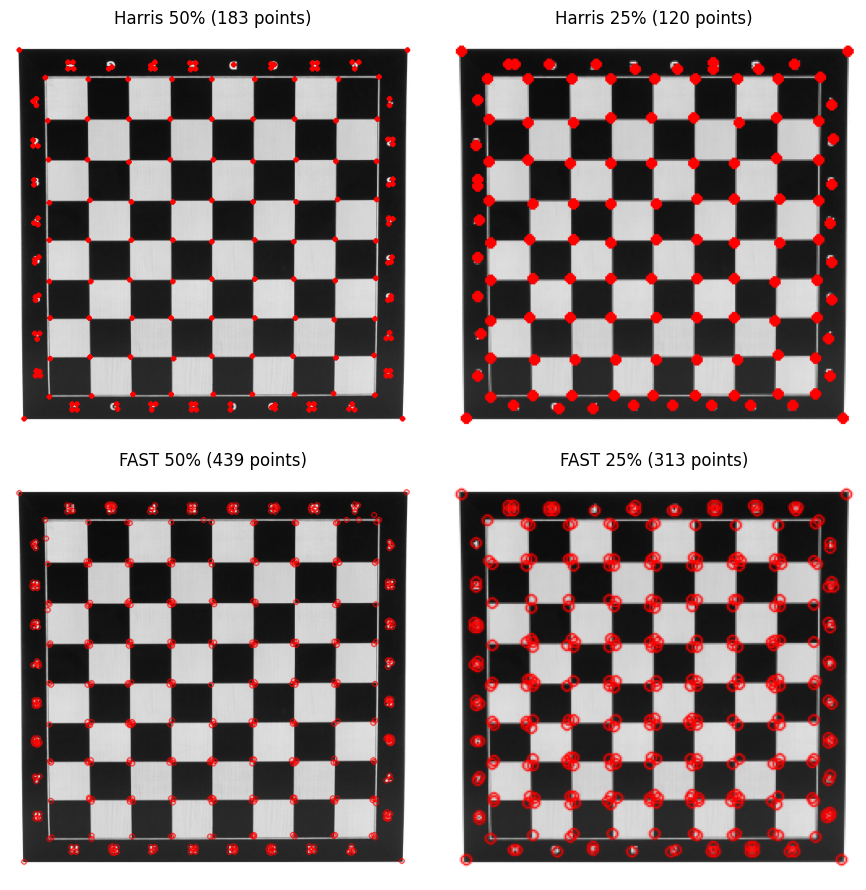

In [7]:
# Resize the image
small_50 = cv2.resize(gray, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
small_25 = cv2.resize(gray, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)

# Count detections at all three sizes
print("Size    Harris    FAST")
for label, picture in [("100%", gray), ("50%", small_50), ("25%", small_25)]:
    h_points = harris_corners(picture, 0.04, 0.01)
    f_points = fast_corners(picture, 20)
    print(f"{label:4}    {len(h_points):5}    {len(f_points):4}")

# Show only the new 50% and 25% results
fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for col, (label, picture) in enumerate([("50%", small_50), ("25%", small_25)]):
    h_points = harris_corners(picture, 0.04, 0.01)
    f_points = fast_corners(picture, 20)

    axes[0, col].imshow(draw_harris(picture, h_points, radius=2))
    axes[0, col].set_title(f"Harris {label} ({len(h_points)} points)")

    fast_image = cv2.drawKeypoints(picture, f_points, None, color=(0, 0, 255))
    axes[1, col].imshow(cv2.cvtColor(fast_image, cv2.COLOR_BGR2RGB))
    axes[1, col].set_title(f"FAST {label} ({len(f_points)} points)")

for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 8. What I learned

- **Sobel:** Gx and Gy show different line directions, while magnitude shows the grid together.
- **Canny:** Higher thresholds gave fewer detected edge pixels.
- **Harris:** Changing `k` and the response threshold changed the detected points.
- **FAST:** A higher brightness threshold detected fewer points. FAST was faster in my timing test.
- **Image size:** Both Harris and FAST detected fewer points when the image was reduced.